[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/philippe-amuzuga/Meca-PY_Ed2026/blob/main/python/P05/P05-1_Figures_CORRIGE.ipynb)

# Figures d'ingénieur

Chapitre 5 du livre *Python pour l'ingénierie mécanique, industrielle et productique*.

## Cadrage

**Contexte industriel.** Votre rapport d'essais aligne des tableaux de chiffres, et la question posée (la méthode converge-t-elle, la pièce tient-elle partout) se perd dans les colonnes ? Vous voudriez une figure qui réponde d'un coup d'œil, avec des axes chiffrés et des unités, lisible une fois imprimée en noir et blanc.

**Objectif terminal.** Ce chapitre montre comment partir de la question pour construire la figure juste, avec matplotlib.

**Objectif instrumental.**

- Construire une figure et choisir le tracé adapté à la question.
- Lire la pente d'une loi en puissance en échelles logarithmiques.
- Composer une planche, et tracer une carte en courbes de niveau.
- Rendre une figure lisible en gris, à la largeur de la page.
- Lire une courbe de traction, une carte de contrôle et une marge de phase.

**Critère de résultat.** Chaque exercice atteint son résultat attendu, que des contrôles du notebook vérifient.

**Vérification.** Beaucoup d'exercices donnent une seconde voie : un calcul fait par deux chemins indépendants est un calcul qu'on peut croire.

**Prérequis.** Les chapitres 3 et 4, après une filière scientifique.

## Source de données

Aucun jeu de données : les valeurs viennent de l'énoncé ou sont engendrées par le code, à graine fixée.

## Exercices

| N° | Exercice | Durée indicative |
|:-|:-|-:|
| 5.1 | Convergence en échelle logarithmique | 10 min |
| 5.2 | Histogramme de cinquante répétitions | 10 min |
| 5.3 | Planche à deux axes jumeaux | 15 min |
| 5.4 | Carte de contrainte d'une plaque trouée | 20 min |
| 5.5 | Trois courbes lisibles en noir et blanc (défi) | 20 min |

Dans le sujet, les cellules marquées `# Votre code :` sont à écrire ; le corrigé les donne résolues. Chaque exercice se termine par des contrôles qui comparent votre résultat à celui du livre.

### En-tête de reproductibilité

Versions des bibliothèques employées : les valeurs du livre sont celles de ces versions, avec des graines fixées.

In [1]:
# En-tête de reproductibilité : versions employées par ce notebook.
import platform
from importlib.metadata import version

print("Python", platform.python_version())
print("matplotlib", version("matplotlib"))
print("numpy", version("numpy"))

Python 3.12.0
matplotlib 3.11.1
numpy 2.4.6


### Préparation du dépôt (Colab)

Ouvert seul dans Colab, ce notebook ne voit pas les dossiers du dépôt. La cellule suivante ne télécharge rien : elle cherche `donnees/` et `outils/` (à deux dossiers au-dessus du notebook, à côté de lui ou dans un clone nommé `Meca-PY_Ed2026`), ajoute `outils/` au chemin de recherche de Python, et, sur Colab, liste ce qui manque. Pour le fournir, ouvrez le panneau des fichiers de Colab, créez les dossiers `donnees` et `outils` à la racine de l'espace de travail, et téléversez-y les fichiers listés, pris dans le dépôt. Ce notebook reproduit le code des modules cités ; les téléverser sert à les importer dans vos propres cellules.

In [2]:
# Préparation du dépôt (utile sur Colab) : cette cellule ne télécharge rien.
import os
import sys
from pathlib import Path

JEUX_LUS = []
MODULES_DU_LIVRE = ["meca_style.py"]                          # fichiers de outils/


def chercher(dossier):
    """Le dossier du dépôt cherché depuis le notebook, puis depuis un clone ; None s'il est introuvable."""
    for base in (Path("..", ".."), Path("."), Path("Meca-PY_Ed2026")):
        if (base / dossier).is_dir():
            return base / dossier
    return None


donnees, outils = chercher("donnees"), chercher("outils")
if outils is not None and str(outils) not in sys.path:
    sys.path.insert(0, str(outils))
manque = [f"donnees/{nom}" for nom in JEUX_LUS if donnees is None or not (donnees / nom).is_file()]
manque += [f"outils/{nom}" for nom in MODULES_DU_LIVRE if outils is None or not (outils / nom).is_file()]
if manque and "COLAB_RELEASE_TAG" in os.environ:          # variable posée par Colab
    print("À téléverser dans l'espace de travail de Colab, panneau des fichiers :")
    print("\n".join("  " + nom for nom in manque))


### Préparation

In [3]:
import io
import re
import tempfile
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import to_rgb
# La plaque du chapitre 4 : 100 x 60 mm, deux trous de 20 mm centrés en (30, 30) et (70, 30).
L, H, R = 100.0, 60.0, 10.0
aire_exacte = L * H - 2 * np.pi * R**2
p = aire_exacte / (L * H)

In [4]:
def aire_plaque(rng, N):
    """Une estimation Monte-Carlo de l'aire de la plaque avec N tirages."""
    x = rng.uniform(0, L, N)
    y = rng.uniform(0, H, N)
    dans_un_trou = ((x - 30)**2 + (y - 30)**2 < R**2) | ((x - 70)**2 + (y - 30)**2 < R**2)
    return L * H * (~dans_un_trou).mean()

def volume_bague(rng, N):
    """Une estimation Monte-Carlo du volume de la bague du chapitre 4 (40 et 20 mm, 10 mm)."""
    x = rng.uniform(-20, 20, N)
    y = rng.uniform(-20, 20, N)
    rayon2 = x**2 + y**2
    return 40 * 40 * 10 * ((rayon2 <= 400) & (rayon2 >= 100)).mean()

### Section 5.1 : l'échelle logarithmique redresse une loi en puissance.

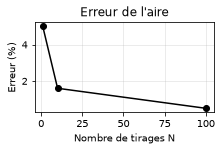

In [5]:
# notion: figure-axes
fig, ax = plt.subplots(figsize=(3.2, 2.2))
ax.plot([1, 10, 100], [5.0, 1.6, 0.5], "o-", color="black")
ax.set_xlabel("Nombre de tirages N")
ax.set_ylabel("Erreur (%)")
ax.set_title("Erreur de l'aire")
ax.grid(alpha=0.3)
fig.tight_layout()
memoire = io.BytesIO()
fig.savefig(memoire, format="pdf")                       # export vectoriel, ici en mémoire
assert memoire.getvalue().startswith(b"%PDF"), "le fichier exporté doit être un PDF"
i = 1                                                  # compteur global et préfixe, comme dans l'export de l'auteur
prefix = "fig05"

In [6]:
def save_plt_as_pdf(figure, dossier):
    """Export numérique de l'auteur, en PDF vectoriel : fig05_01.pdf, fig05_02.pdf, ..."""
    global i, prefix
    num = str(i).zfill(2) if i < 10 else str(i)
    nom = Path(dossier) / f"{prefix}_{num}.pdf"
    figure.savefig(nom)
    i += 1
    return nom

def style_axes(ax):
    """Style d'axes de l'auteur : la grille passe sous les tracés, les filets font 1 pt."""
    ax.set_axisbelow(True)
    for spine in ax.spines.values():
        spine.set_linewidth(1.0)

style_axes(ax)
assert ax.get_axisbelow() is True and all(s.get_linewidth() == 1.0 for s in ax.spines.values())

In [7]:
with tempfile.TemporaryDirectory() as dossier_export:
    premier = save_plt_as_pdf(fig, dossier_export)
    second = save_plt_as_pdf(fig, dossier_export)
    assert (
        (premier.name, second.name) == ("fig05_01.pdf", "fig05_02.pdf") and premier.stat().st_size > 1000
    )

In [8]:
# notion: anatomie
assert (
    fig.axes == [ax] and len(ax.lines) == 1
), "une Figure contient des Axes, les Axes contiennent des tracés"
assert ax.get_xlabel() == "Nombre de tirages N" and ax.get_title() == "Erreur de l'aire"
print("anatomie : 1 Figure, %d Axes, %d courbe, étiquette x « %s »" % (len(fig.axes), len(ax.lines), ax.get_xlabel()))
plt.close(fig)

anatomie : 1 Figure, 1 Axes, 1 courbe, étiquette x « Nombre de tirages N »


In [9]:
# notion: echelle-log
fig, ax = plt.subplots(figsize=(3.2, 2.2))
ax.plot([1, 10, 100], [5.0, 1.6, 0.5])
ax.set_yscale("log")
assert ax.get_yscale() == "log"
plt.close(fig)

In [10]:
# notion: polyfit
x_demo = np.array([1.0, 10.0, 100.0, 1000.0])
y_demo = 3.0 * x_demo**(-0.5)
pente_demo, ordonnee_demo = np.polyfit(np.log10(x_demo), np.log10(y_demo), 1)
assert (
    abs(pente_demo + 0.5) < 1e-12 and abs(np.polyval([pente_demo, ordonnee_demo], 0.0) - np.log10(3.0)) < 1e-12
)

## Exercice 5.1 : Convergence en échelle logarithmique (10 min)

L'écart-type relatif de l'aire de la plaque du chapitre 4 décroît-il comme l'inverse de la racine du nombre de tirages ? Pour $N = 100$, $1\,000$, $10\,000$ et $100\,000$ tirages, estimez-le sur $50$ répétitions (graine $2026$), tracez-le en échelles logarithmiques avec des axes nommés et chiffrés en unités, puis lisez la pente de la droite entre les deux extrêmes (figure du chapitre).

**Résultat attendu.** Pente de $-0{,}51$, proche de la valeur théorique, moins un demi ; écart-type relatif de 3,31 % à $100$ tirages et de 0,098 % à $100\,000$ tirages.

**Seconde voie.** La droite ajustée par `np.polyfit` sur les quatre points donne la même pente à deux décimales, $-0{,}51$.

**Indication.** Pour chaque taille, une boucle remplit un tableau de $50$ estimations et en garde l'écart-type relatif. La pente se lit entre les extrêmes : différence des logarithmes décimaux des écarts-types, divisée par la différence des logarithmes des tailles. La figure se trace avec `ax.loglog`.

Les contrôles de la cellule lisent les variables `pente`, `pente_ajustee` : gardez ces noms.

In [11]:
# Solution :
rng = np.random.default_rng(2026)
tailles = [100, 1000, 10000, 100000]
dispersion = []                                  # écart-type relatif, pour chaque N

for N in tailles:
    estimations = np.zeros(50)
    for k in range(50):
        estimations[k] = aire_plaque(rng, N)
    dispersion.append(estimations.std(ddof=1) / aire_exacte)

for N, s in zip(tailles, dispersion):
    print(f"N = {N:>6} : écart-type relatif {100 * s:.3f} %")

montee = np.log10(dispersion[-1]) - np.log10(dispersion[0])     # en décades d'écart-type
course = np.log10(tailles[-1]) - np.log10(tailles[0])           # en décades de N
pente = montee / course
pente_ajustee = np.polyfit(np.log10(tailles), np.log10(dispersion), 1)[0]
print(f"pente lue en log-log : {pente:.2f} (théorie : -0.50)")
print(f"pente de la droite ajustée par np.polyfit : {pente_ajustee:.2f}")
fig, ax = plt.subplots(figsize=(3.2, 2.2))
ax.loglog(tailles, dispersion, "o-", color="black")
ax.set_xlabel("Nombre de tirages N")
ax.set_ylabel("Écart-type relatif (-)")
ax.grid(alpha=0.3, which="both")
plt.close(fig)
# Fin de la solution
assert abs(pente - (-0.50)) < 0.06, "pente attendue : -0,50 à 0,06 près"
assert abs(pente_ajustee - (-0.50)) < 0.06, "pente ajustée attendue : -0,50 à 0,06 près"
print("Exercice 5.1 : contrôles passés")

N =    100 : écart-type relatif 3.308 %
N =   1000 : écart-type relatif 1.147 %
N =  10000 : écart-type relatif 0.331 %
N = 100000 : écart-type relatif 0.098 %
pente lue en log-log : -0.51 (théorie : -0.50)
pente de la droite ajustée par np.polyfit : -0.51
Exercice 5.1 : contrôles passés


### Section 5.2 : un histogramme montre la dispersion d'un coup d'oeil.

In [12]:
# notion: nuage-courbe
rng_demo = np.random.default_rng(5)
x_nuage = np.linspace(0.0, 10.0, 30)
y_nuage = 2.0 * x_nuage + rng_demo.normal(0.0, 1.0, 30)
fig, (g1, g2, g3, g4) = plt.subplots(1, 4, figsize=(6.4, 1.8))
g1.scatter(x_nuage, y_nuage, s=6)
g2.plot(x_nuage, 2.0 * x_nuage)
g3.boxplot(y_nuage)
g4.barh(["A", "B", "C"], [3.0, 1.0, 2.0])
assert len(g1.collections) == 1 and len(g2.lines) == 1 and len(g4.patches) == 3
assert len(g3.lines) >= 5, "la boîte dessine médiane, moustaches et boîte"
plt.close(fig)

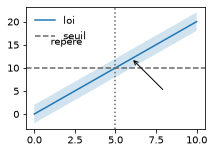

In [13]:
# notion: legende
fig, ax = plt.subplots(figsize=(3.2, 2.2))
ax.plot(x_nuage, 2.0 * x_nuage, label="loi")
ax.axhline(10.0, color="0.4", linestyle="dashed", label="seuil")
ax.axvline(5.0, color="0.4", linestyle="dotted")
ax.text(1.0, 15.0, "repère")
ax.annotate("", xy=(6.0, 12.0), xytext=(8.0, 5.0), arrowprops=dict(arrowstyle="->"))
ax.fill_between(x_nuage, 2.0 * x_nuage - 2.0, 2.0 * x_nuage + 2.0, alpha=0.2)
legende = ax.legend(frameon=False)
assert (
    [t.get_text() for t in legende.get_texts()] == ["loi", "seuil"]
), "les tracés nommés entrent en légende"

In [14]:
def center_spines(ax):
    """Axes de l'auteur qui se croisent à l'origine, grille en tirets (courbes d'activation, fonctions impaires)."""
    ax.spines["left"].set_position("zero")
    ax.spines["bottom"].set_position("zero")
    ax.spines["right"].set_color("none")
    ax.spines["top"].set_color("none")
    ax.xaxis.set_ticks_position("bottom")
    ax.yaxis.set_ticks_position("left")
    ax.grid(True, which="both", linestyle="dashed", alpha=0.35)

center_spines(ax)
assert (
    ax.spines["left"].get_position() == "zero" and ax.spines["bottom"].get_position() == "zero"
)
plt.close(fig)

## Exercice 5.2 : Histogramme de cinquante répétitions (10 min)

Répétez $50$ fois l'estimation de l'aire avec $10\,000$ tirages (graine $2026$). Tracez l'histogramme en $10$ classes et marquez l'aire exacte par un trait vertical en tirets (figure du chapitre). Comparez l'écart-type observé à l'écart-type attendu.

**Résultat attendu.** Moyenne de 5 373,2 mm², écart-type observé de 21,5 mm² pour 18,4 mm² attendus.

**Indication.** `ax.hist(valeurs, bins=10)` rend les effectifs des classes, dont la somme est le nombre de répétitions. `ax.axvline` trace le trait vertical. L'écart-type attendu vaut l'aire du rectangle multipliée par $\sqrt{p(1-p)/N}$, où $p$ est la proportion de matière.

Les contrôles de la cellule lisent les variables `ecart_type_mesure`, `effectifs`, `sigma_theorie` : gardez ces noms.

In [15]:
# Solution :
rng = np.random.default_rng(2026)
N = 10000
repetees = np.zeros(50)

for k in range(50):
    repetees[k] = aire_plaque(rng, N)

ecart_type_mesure = repetees.std(ddof=1)
sigma_theorie = L * H * np.sqrt(p * (1 - p) / N)
fig, ax = plt.subplots(figsize=(3.2, 2.2))
effectifs, bornes, barres = ax.hist(repetees, bins=10, color="0.6", edgecolor="black")
ax.axvline(aire_exacte, color="black", linestyle="dashed", label="aire exacte")
ax.set_xlabel("Aire estimée (mm²)")
ax.set_ylabel("Nombre de répétitions")
ax.legend(frameon=False)
plt.close(fig)
print("effectifs des 10 classes :", effectifs.astype(int).tolist())
print(f"moyenne : {repetees.mean():.1f} mm², écart-type : {ecart_type_mesure:.1f} mm²")
print(f"écart-type attendu : {sigma_theorie:.1f} mm²")
# Fin de la solution
assert effectifs.sum() == 50, "l'histogramme doit compter les 50 répétitions"
assert abs(ecart_type_mesure - sigma_theorie) < 0.3 * sigma_theorie, "écart-type hors de 30 %"
print("Exercice 5.2 : contrôles passés")

effectifs des 10 classes : [3, 7, 4, 9, 10, 7, 6, 2, 0, 2]
moyenne : 5373.2 mm², écart-type : 21.5 mm²
écart-type attendu : 18.4 mm²
Exercice 5.2 : contrôles passés


### Section 5.3 : plusieurs graphiques se composent en une planche.

In [16]:
# notion: mosaique
fig, axes = plt.subplot_mosaic([["haut", "haut"], ["gauche", "droite"]], figsize=(4.0, 3.0), sharex=False)
assert sorted(axes) == ["droite", "gauche", "haut"] and len(fig.axes) == 3
plt.close(fig)
fig, (a1, a2) = plt.subplots(2, 1, sharex=True, figsize=(3.2, 3.0))
a1.plot([0, 1], [0, 1])
a2.plot([0.2, 0.8], [1, 0])
assert a1.get_xlim() == a2.get_xlim(), "axes partagés : les deux échelles x sont liées"
plt.close(fig)

## Exercice 5.3 : Planche à deux axes jumeaux (15 min)

La même poutre, de largeur $20$ mm, porte $2$ kN en son milieu sur $1$ m, avec $E = 210\,000$ MPa. La hauteur $h$ de sa section varie de $20$ à $80$ mm. Tracez la flèche et la contrainte maximale selon $h$, sur deux axes jumeaux. Quelle hauteur minimale respecte à la fois une flèche d'au plus $2$ mm ($L/500$) et une contrainte d'au plus $160$ MPa ? Cherchez-la d'abord sur une grille de $0{,}1$ mm, puis par la formule (figure du chapitre).

**Résultat attendu.** À $h = 40$ mm, flèche de 1,86 mm et contrainte de 93,75 MPa ; hauteur minimale de 39,04 mm pour la flèche et de 30,62 mm pour la contrainte, donc 39,04 mm (39,1 mm sur la grille).

**Seconde voie.** La grille au pas de $0{,}1$ mm retombe sur la formule, 39,1 mm contre 39,04 mm : l'écart est inférieur au pas.

**Indication.** Avec $I = b\,h^3/12$, la flèche vaut $F L^3/(48\,E\,I)$ et la contrainte $3\,F L/(2\,b\,h^2)$. On tabule $h$ avec `np.linspace(20, 80, 601)`, on calcule les deux grandeurs, et le masque `(fleche <= 2) & (sigma <= 160)` garde les hauteurs admissibles : la première est la réponse sur la grille. La formule isole $h$ dans chaque limite, et la plus grande des deux hauteurs l'emporte : c'est la flèche.

In [17]:
F_N, L_mm, b_mm, E_MPa = 2000.0, 1000.0, 20.0, 210000.0
# Solution :
fleche_max_mm, sigma_adm_MPa = L_mm / 500, 160.0
h = np.linspace(20.0, 80.0, 601)                              # hauteurs de 20 à 80 mm, pas de 0,1 mm
fleche = F_N * L_mm**3 / (48 * E_MPa * b_mm * h**3 / 12)      # F L³ / (48 E I), I = b h³ / 12
sigma = 3 * F_N * L_mm / (2 * b_mm * h**2)                    # M = F L / 4, sigma = M (h/2) / I
fig, ax_f = plt.subplots(figsize=(3.2, 2.2))
ax_f.plot(h, fleche, color="black", label="flèche")
ax_f.set_xlabel("Hauteur h (mm)")
ax_f.set_ylabel("Flèche (mm)")
ax_s = ax_f.twinx()                                           # axes jumeaux : même abscisse, autre ordonnée
ax_s.plot(h, sigma, color="0.5", linestyle="dashed", label="contrainte")
ax_s.set_ylabel("Contrainte (MPa)")
# Fin de la solution
assert len(fig.axes) == 2 and ax_f.get_xlim() == ax_s.get_xlim(), "deux axes, une seule abscisse"
# Solution :
plt.close(fig)
ok = (fleche <= fleche_max_mm) & (sigma <= sigma_adm_MPa)
h_mini_grille = h[ok][0]                                      # premier point de la grille qui respecte les deux
h_flexion = (12 * F_N * L_mm**3 / (48 * E_MPa * b_mm * fleche_max_mm))**(1 / 3)       # flèche exacte égale à L/500
h_contrainte = np.sqrt(3 * F_N * L_mm / (2 * b_mm * sigma_adm_MPa))                  # contrainte exacte égale à 160 MPa
h_mini = max(h_flexion, h_contrainte)
k40 = int(np.argmin(np.abs(h - 40.0)))                       # indice du point de la grille le plus proche de 40 mm
fleche_40 = float(fleche[k40])
sigma_40 = float(sigma[k40])
print(f"flèche à h = 40 mm : {fleche_40:.2f} mm ; contrainte : {sigma_40:.2f} MPa")
print(f"hauteur minimale pour la flèche : {h_flexion:.2f} mm ; pour la contrainte : {h_contrainte:.2f} mm")
print(f"hauteur minimale retenue : {h_mini:.2f} mm (grille au pas de 0,1 mm : {h_mini_grille:.1f} mm)")
# Fin de la solution
assert abs(sigma_40 - 93.75) < 0.01, "contrainte attendue à h = 40 mm : 93,75 MPa"
assert h_flexion > h_contrainte, "c'est la flèche qui impose la hauteur"
assert (
    abs(h_mini_grille - h_mini) < 0.1 + 1e-9 and h_mini_grille >= h_mini
), "grille et formule concordent"
print("Exercice 5.3 : contrôles passés")

flèche à h = 40 mm : 1.86 mm ; contrainte : 93.75 MPa
hauteur minimale pour la flèche : 39.04 mm ; pour la contrainte : 30.62 mm
hauteur minimale retenue : 39.04 mm (grille au pas de 0,1 mm : 39.1 mm)
Exercice 5.3 : contrôles passés


### Section 5.4 : une carte de contraintes se lit en courbes de niveau.

In [18]:
# notion: grille
xg = np.linspace(-1.0, 1.0, 5)
X_demo, Y_demo = np.meshgrid(xg, xg)
Z_demo = X_demo**2 + Y_demo**2
assert (
    X_demo.shape == (5, 5) and Z_demo[2, 2] == 0.0 and Z_demo[0, 0] == 2.0
), "une valeur par noeud"

In [19]:
# notion: contours
fig, ax = plt.subplots(figsize=(3.2, 2.6))
cs_demo = ax.contour(X_demo, Y_demo, Z_demo)
trace = ax.contourf(X_demo, Y_demo, Z_demo)
barre = fig.colorbar(trace, ax=ax)
assert len(cs_demo.levels) >= 3 and barre is not None
plt.close(fig)

In [20]:
# notion: imshow
fig, ax = plt.subplots(figsize=(3.2, 2.6))
image = ax.imshow(Z_demo, extent=(-1, 1, -1, 1), origin="lower")
fig.colorbar(image, ax=ax)
assert image.get_array().shape == (5, 5)
plt.close(fig)

## Exercice 5.4 : Carte de contrainte d'une plaque trouée (20 min)

Une plaque très large, tendue à $100$ MPa selon $x$, est percée d'un trou de rayon $a = 10$ mm. Loin du trou, la contrainte reste égale à celle imposée ; près du trou, elle augmente. Sa composante $\sigma_{xx}$ au point de coordonnées polaires $(r, \theta)$, avec $r \ge a$, vaut

$$\sigma_{xx} = \sigma_\infty\left[1 - \frac{a^2}{r^2}\left(\frac{3}{2}\cos 2\theta + \cos 4\theta\right) + \frac{3}{2}\,\frac{a^4}{r^4}\cos 4\theta\right]$$

(solution de Kirsch, 1898). Sur une grille de $-40$ à $40$ mm au pas de 0,5 mm, calculez $\sigma_{xx}$ (le trou reste vide, ses nœuds valent `np.nan`) et tracez-la en 11 niveaux, de $50$ à $300$ MPa tous les $25$ MPa, avec `extend="both"` pour colorer aussi les valeurs hors niveaux. Quelle est la contrainte maximale, et quel coefficient de concentration $K_t$ donne-t-elle ? Comparez-le à celui de la formule de Heywood du chapitre 3 pour un trou de $1\,\%$ de la largeur.

**Résultat attendu.** Grille de 25 921 nœuds ; maximum de 300,0 MPa au sommet du trou, soit $K_t = 3{,}0$ ; formule de Heywood pour $d/W = 0{,}01$ : 2,97, proche de $3$ (figure du chapitre).

**Seconde voie.** Au sommet du trou, en $(0~;~a)$, la formule donne $300{,}0$ MPa : $\theta = 90^\circ$, $r = a$, et les termes entre crochets valent $1 + \tfrac12 + \tfrac32 = 3$.

**Indication.** Construisez $x$ et $y$ avec `np.linspace(-40, 40, 161)`, puis `np.meshgrid`. Calculez $r$ et $\theta = \texttt{np.arctan2}(Y, X)$, remplacez par `np.nan` les nœuds où $r < a$ avant de diviser, et appliquez la formule. Le maximum de la grille, `np.nanmax`, tombe sur un nœud du bord du trou. Tracez avec `ax.contourf(X, Y, champ, levels=niveaux, extend="both")` et `fig.colorbar`.

Les contrôles de la cellule lisent les variables `bord_cote`, `bord_haut`, `kt_heywood_petit`, `loin`, `maximum_grille` : gardez ces noms.

In [21]:
sigma_inf_MPa, a_mm = 100.0, 10.0
# Solution :
def kirsch_sxx(x, y, sigma_inf, a):
    """Contrainte sigma_xx de la plaque infinie trouée, tendue selon x (solution de Kirsch)."""
    r2 = np.where(x**2 + y**2 == 0, np.nan, x**2 + y**2)         # le centre n'a pas de valeur
    theta = np.arctan2(y, x)
    u = a**2 / r2
    s_r = sigma_inf / 2 * (1 - u) + sigma_inf / 2 * (1 - 4 * u + 3 * u**2) * np.cos(2 * theta)
    s_t = sigma_inf / 2 * (1 + u) - sigma_inf / 2 * (1 + 3 * u**2) * np.cos(2 * theta)
    t_rt = -sigma_inf / 2 * (1 + 2 * u - 3 * u**2) * np.sin(2 * theta)
    return s_r * np.cos(theta)**2 + s_t * np.sin(theta)**2 - 2 * t_rt * np.sin(theta) * np.cos(theta)

x = np.linspace(-40.0, 40.0, 161)
y = np.linspace(-40.0, 40.0, 161)
X, Y = np.meshgrid(x, y)
rayon = np.sqrt(X**2 + Y**2)
dans_le_trou = rayon < a_mm
champ = np.where(dans_le_trou, np.nan, kirsch_sxx(X, Y, sigma_inf_MPa, a_mm))
niveaux = np.arange(50.0, 301.0, 25.0)
fig, ax = plt.subplots(figsize=(3.2, 2.8))
cs = ax.contourf(X, Y, champ, levels=niveaux, extend="both")
fig.colorbar(cs, ax=ax, label="Contrainte (MPa)")
ax.set_aspect("equal")
plt.close(fig)
maximum_grille = float(np.nanmax(champ))
bord_haut = float(kirsch_sxx(0.0, a_mm, sigma_inf_MPa, a_mm))          # point (0, a), sommet du trou
bord_cote = float(kirsch_sxx(a_mm, 0.0, sigma_inf_MPa, a_mm))          # point (a, 0), côté du trou
loin = float(kirsch_sxx(1000.0, 0.0, sigma_inf_MPa, a_mm))
print(f"grille {X.shape[0]} x {X.shape[1]}, {int(dans_le_trou.sum())} noeuds dans le trou, {len(niveaux)} niveaux")
print(f"contrainte maximale de la grille : {maximum_grille:.1f} MPa, soit Kt = {maximum_grille / sigma_inf_MPa:.2f}")
print(f"au sommet du trou (0, a) : {bord_haut:.1f} MPa ; au côté du trou (a, 0) : {bord_cote:.1f} MPa ; loin : {loin:.1f} MPa")
kt_heywood_petit = 2 + (1 - 0.01)**3                          # trou de 1 % de la largeur
print(f"Kt de Heywood pour d/W = 0,01 : {kt_heywood_petit:.2f} (plaque infinie : 3)")
# Fin de la solution
assert abs(bord_haut - 3 * sigma_inf_MPa) < 1e-9, "Kt = 3 au sommet du trou"
assert (
    abs(maximum_grille - 3 * sigma_inf_MPa) < 1e-9
), "le maximum de la grille tombe sur un noeud du bord"
assert (
    abs(bord_cote) < 1e-9
), "côté du trou, sigma_xx est nulle : le bord est libre dans cette direction"
assert (
    abs(loin - sigma_inf_MPa) < 0.01 * sigma_inf_MPa
), "loin du trou, la contrainte revient à sa valeur imposée"
assert abs(kt_heywood_petit - 3.0) < 0.04, "Heywood tend vers 3 pour un petit trou"
print("Exercice 5.4 : contrôles passés")

grille 161 x 161, 1245 noeuds dans le trou, 11 niveaux
contrainte maximale de la grille : 300.0 MPa, soit Kt = 3.00
au sommet du trou (0, a) : 300.0 MPa ; au côté du trou (a, 0) : 0.0 MPa ; loin : 100.0 MPa
Kt de Heywood pour d/W = 0,01 : 2.97 (plaque infinie : 3)
Exercice 5.4 : contrôles passés


### Section 5.5 : une figure imprimée doit rester lisible en gris.

In [22]:
# notion: mplstyle
feuille = "font.size : 8\naxes.grid : True\ngrid.alpha : 0.3\nlines.linewidth : 1.2\npdf.fonttype : 42\n"

with tempfile.TemporaryDirectory() as dossier:
    chemin_style = Path(dossier) / "livre.mplstyle"
    chemin_style.write_text(feuille)
    with plt.style.context(str(chemin_style)):                 # le style ne vaut que dans ce bloc
        assert plt.rcParams["font.size"] == 8 and plt.rcParams["axes.grid"] is True
        # notion: pdf-vectoriel
        largeur_in = 361.35 / 72.27                             # largeur du texte du livre : 361,35 pt TeX, soit 5 pouces
        fig, ax = plt.subplots(figsize=(largeur_in, 0.55 * largeur_in))
        ax.plot([0, 1], [0, 1], label="trait")
        ax.legend()
        memoire = io.BytesIO()
        fig.savefig(memoire, format="pdf")
        plt.close(fig)

octets = memoire.getvalue()

In [23]:
boite = re.search(rb"/MediaBox\s*\[\s*0\s+0\s+([0-9.]+)\s+([0-9.]+)\s*\]", octets)
largeur_pdf = float(boite.group(1))
print(f"page du PDF exporté : {largeur_pdf:.2f} x {float(boite.group(2)):.2f} pt (1 pouce = 72 pt)")
assert abs(largeur_pdf - 360.0) < 0.01, "5 pouces font 360 pt de PDF, soit 361,35 pt TeX"
assert b"/Type3" not in octets, "polices TrueType incorporées, aucune police de type 3"
assert (
    plt.rcParams["font.size"] != 8 or plt.rcParams["axes.grid"] is False
), "le style ne sort pas de son bloc"

page du PDF exporté : 360.00 x 198.00 pt (1 pouce = 72 pt)


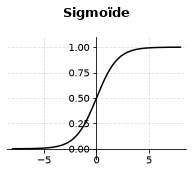

In [24]:
def format_ax(ax, title, y_lims):
    """Mise en forme d'axes de l'auteur : axes à l'origine, grille en tirets, titre, limites verticales."""
    ax.spines["left"].set_position("zero")
    ax.spines["bottom"].set_position("zero")
    ax.spines["right"].set_color("none")
    ax.spines["top"].set_color("none")
    ax.grid(True, which="both", linestyle="dashed", alpha=0.4)
    ax.set_title(title, fontsize=13, pad=20)
    ax.title.set_fontweight("bold")
    ax.set_ylim(y_lims)
    ax.set_xlim(-8.5, 8.5)

fig, ax = plt.subplots(figsize=(3.2, 2.2))
t_ = np.linspace(-8.0, 8.0, 161)
format_ax(ax, "Sigmoïde", (-0.1, 1.1))
ax.plot(t_, 1 / (1 + np.exp(-t_)), color="black")

In [25]:
assert (
    ax.get_title() == "Sigmoïde" and ax.get_ylim() == (-0.1, 1.1) and ax.get_xlim() == (-8.5, 8.5)
)
plt.close(fig)

## Exercice 5.5 : Trois courbes lisibles en noir et blanc (défi, 20 min)

Superposez sur une figure l'écart-type relatif de l'aire de la plaque, celui du volume de la bague et la loi théorique de la plaque, pour les mêmes tailles qu'à l'exercice 5.1. Chaque courbe doit se distinguer par son niveau de gris et par son style de trait. Mesurez la luminance de chaque couleur, de $0$ (noir) à $255$ (blanc), avec la pondération $0{,}299\,R + 0{,}587\,V + 0{,}114\,B$, et vérifiez que deux couleurs ne diffèrent jamais de moins de $50$ niveaux.

**Résultat attendu.** Niveaux de gris de 0, 100 et 152 pour `"black"`, `"tab:blue"` et `"tab:orange"` ; plus petit écart de 52 niveaux.

**Indication.** Donnez à chaque courbe un trait différent (plein, tirets, pointillés) et, au besoin, un marqueur. Convertissez chaque couleur en composantes rouge, vert et bleu avec `matplotlib.colors.to_rgb`, appliquez la pondération, et comparez les niveaux deux à deux.

Les contrôles de la cellule lisent les variables `differences_gris`, `traits` : gardez ces noms.

In [26]:
# Solution :
rng = np.random.default_rng(2026)
disp_bague = []
theorie = []

for N in tailles:
    volumes = np.zeros(50)
    for k in range(50):
        volumes[k] = volume_bague(rng, N)
    disp_bague.append(volumes.std(ddof=1) / volumes.mean())
    theorie.append(np.sqrt((1 - p) / (p * N)))      # loi théorique de la plaque

styles = [("plaque", "black", "solid", "o"),
          ("bague", "tab:blue", "dashed", "s"),
          ("théorie, plaque", "tab:orange", "dotted", "")]
series = [dispersion, disp_bague, theorie]
fig, ax = plt.subplots(figsize=(3.2, 2.2))

for i in range(3):
    nom, couleur, trait, marque = styles[i]
    ax.loglog(tailles, series[i], color=couleur, linestyle=trait, marker=marque, label=nom)

ax.set_xlabel("Nombre de tirages N")
ax.set_ylabel("Écart-type relatif (-)")
ax.legend(frameon=False)
plt.close(fig)
gris = []
traits = []

for nom, couleur, trait, marque in styles:
    r, v, b = to_rgb(couleur)
    gris.append(round(255 * (0.299 * r + 0.587 * v + 0.114 * b)))   # luminance perçue, 0 à 255
    traits.append(trait)
    print(f"{nom:>16} : couleur {couleur:<10} gris {gris[-1]:>3}, trait {trait!r}")

differences_gris = [abs(gris[0] - gris[1]), abs(gris[0] - gris[2]), abs(gris[1] - gris[2])]
print("plus petit écart de gris entre deux courbes :", min(differences_gris), "niveaux sur 255")
# Fin de la solution
assert min(differences_gris) >= 50, "deux courbes ont des gris trop proches"
assert len(set(traits)) == 3, "chaque courbe doit avoir son style de trait"
print("Exercice 5.5 : contrôles passés")

          plaque : couleur black      gris   0, trait 'solid'
           bague : couleur tab:blue   gris 100, trait 'dashed'
 théorie, plaque : couleur tab:orange gris 152, trait 'dotted'
plus petit écart de gris entre deux courbes : 52 niveaux sur 255
Exercice 5.5 : contrôles passés


### Le module `meca_style.py`

Les figures qui suivent emploient le module `meca_style.py` du livre (dossier `outils/` du dépôt). Son texte complet est donné ci-dessous ; la cellule d'après l'écrit dans un dossier temporaire et l'importe, comme au chapitre 19, de sorte que le notebook se lance aussi hors du dépôt cloné. Les figures sont enregistrées dans un autre dossier temporaire, effacé à la fermeture de Python.

In [27]:
TEXTE_STYLE = r'''# SPDX-License-Identifier: MIT
"""meca_style : le style des figures du livre, appliqué en une ligne.

Usage, après avoir ajouté `outils/` au chemin de recherche des modules :

    import meca_style as ms
    ms.appliquer()                 # matplotlib : polices de 7 à 7,5 pt, grille horizontale, deux couleurs
    ms.appliquer(seaborn=True)     # seaborn : même feuille, passée à sns.set_theme

Le module fournit aussi :

    ms.virgule(ax)                 # virgule décimale sur les graduations de l'axe vertical
    ms.virgule(ax, "xy", ".2f")    # idem sur les deux axes, avec deux décimales (axe, format)
    ms.virgule(fig, "xy")          # idem sur tous les axes d'une figure (ou d'une grille seaborn)
    ms.graduations(ax, 3)          # au plus 3 graduations par axe (ax, nombre, axe)
    ms.BLEU, ms.ORANGE, ms.GRIS    # les teintes du livre ; ms.PALE : un aplat clair
    ms.FLECHE                      # flèche d'annotation : ax.annotate(texte, xy, xytext, arrowprops=ms.FLECHE)
    ms.CARTE                       # dégradé de bleus pour un champ ; ms.VIRGULE : format d'une barre de couleur
    ms.police_min()                # plus petite taille de graduation en vigueur (7.0)

Tout est lisible en une page : ce fichier est la seule source des réglages que les figures du livre
n'écrivent plus une à une.

>>> import meca_style as ms
>>> ms.appliquer()
>>> import matplotlib.pyplot as plt
>>> plt.rcParams["xtick.labelsize"]
7.0
>>> ms.police_min()
7.0
>>> fig, ax = plt.subplots()
>>> ax.plot([0.5, 1.5], [0.25, 0.75])[0].get_color()
'#0B3D6B'
>>> reperes = ax.set_xticks([0.5, 1.5])
>>> ms.virgule(ax, "xy", ".1f")
>>> fig.canvas.draw()
>>> [t.get_text() for t in ax.get_xticklabels()]
['0,5', '1,5']
"""
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.axes import Axes
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.figure import Figure
from matplotlib.ticker import FuncFormatter, MaxNLocator

BLEU, ORANGE, GRIS, PALE = "#0B3D6B", "#D2691E", "#444444", "#E6EEF8"
FLECHE = {"arrowstyle": "->", "color": BLEU}
CARTE = LinearSegmentedColormap.from_list("bleus", ["#D6E4F0", "#2F6FB3", BLEU])
VIRGULE = FuncFormatter(lambda v, _: f"{v:g}".replace(".", ","))

REGLAGES = {
    "font.size": 7.5, "axes.labelsize": 7.5, "axes.titlesize": 7.5,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True,
    "grid.color": "#E2E2E2", "grid.linewidth": 0.4,
    "axes.prop_cycle": plt.cycler(color=[BLEU, ORANGE]),
    "lines.linewidth": 1.2, "patch.linewidth": 0.7, "lines.markersize": 3, "lines.color": GRIS,
    "hatch.color": GRIS,
    "pdf.fonttype": 42,
}


def appliquer(seaborn=False):
    """Active la feuille de style ; avec seaborn=True, la passe aussi à sns.set_theme."""
    if seaborn:
        import seaborn as sns
        police = plt.rcParams["font.family"]                    # seaborn la remet à zéro sinon
        rc = {**REGLAGES, "font.family": police, "axes.linewidth": 0.6, "axes.edgecolor": "#2B2B2B"}
        sns.set_theme(style="white", palette=[BLEU, ORANGE], rc=rc)
    else:
        plt.rcParams.update(REGLAGES)


def police_min():
    """Plus petite taille de graduation en vigueur, en points (7.0 avec la feuille du livre)."""
    return float(min(plt.rcParams["xtick.labelsize"], plt.rcParams["ytick.labelsize"]))


def _axes(cible):
    """Les axes d'une cible : un axe, une liste ou un tableau d'axes, une figure ou une grille seaborn."""
    if isinstance(cible, Axes):
        return [cible]
    if isinstance(cible, Figure):
        return cible.get_axes()
    if hasattr(cible, "figure"):                       # grille seaborn (FacetGrid, PairGrid)
        return cible.figure.get_axes()
    return [a for a in np.ravel(cible) if a is not None]


def virgule(cible, axe="y", fmt="g"):
    """Virgule décimale sur les graduations : axe vaut "x", "y", "z" ou une combinaison ("xy"), fmt est le format."""
    virg = FuncFormatter(lambda v, _: f"{v:{fmt}}".replace(".", ","))
    for ax in _axes(cible):
        if "x" in axe:
            ax.xaxis.set_major_formatter(virg)
        if "y" in axe:
            ax.yaxis.set_major_formatter(virg)
        if "z" in axe and hasattr(ax, "zaxis"):
            ax.zaxis.set_major_formatter(virg)


def graduations(cible, nombre, axe="xy"):
    """Au plus `nombre` graduations sur l'axe "x", "y" ou "xy" de chaque axe de la cible."""
    for ax in _axes(cible):
        if "x" in axe:
            ax.xaxis.set_major_locator(MaxNLocator(nombre))
        if "y" in axe:
            ax.yaxis.set_major_locator(MaxNLocator(nombre))
'''

In [28]:
import atexit
import shutil
import sys
import tempfile
from pathlib import Path

DOSSIER_STYLE = Path(tempfile.mkdtemp(prefix="meca_style_"))
atexit.register(shutil.rmtree, DOSSIER_STYLE, ignore_errors=True)       # effacé à la fermeture de Python
(DOSSIER_STYLE / "meca_style.py").write_text(TEXTE_STYLE, encoding="utf-8")
sys.path.insert(0, str(DOSSIER_STYLE))
DOSSIER_FIGURES = Path(tempfile.mkdtemp(prefix="figures_"))
atexit.register(shutil.rmtree, DOSSIER_FIGURES, ignore_errors=True)

## Sections 5.6 et 5.7 : les figures du livre avec `meca_style`

Les cellules suivantes reprennent, ligne pour ligne, les blocs de code des sections 5.6 (des mesures à la figure) et 5.7 (figures de métier) du livre : un bloc de calcul puis un bloc de tracé pour chaque figure. Seule retouche : l'enregistrement de la figure se fait dans un dossier temporaire.

### Des mesures à la figure

In [29]:
import sys
sys.path.insert(0, "outils")             # le dossier outils/ du dépôt
import meca_style as ms
ms.appliquer()
print("police minimale :", ms.police_min(), "pt")

police minimale : 7.0 pt


#### Trois poutres sur une échelle

In [30]:
# Poutre encastrée sous charge répartie uniforme de 600 N/m.
module, inertie, charge = 210e9, 8e-8, 600.0
longueurs = [0.6, 0.8, 1.0]
k = 1000 * charge / (24 * module * inertie)

# Profils de flèche le long de la poutre et flèches en bout.
courbes = []
for lg in longueurs:
    x = np.linspace(0, lg, 101)
    y = k * x**2 * (6 * lg**2 - 4 * lg * x + x**2)
    courbes.append((x, y))
bouts = [f"{y[-1]:.2f}".replace(".", ",") for _, y in courbes]
print("flèches en bout (mm) :", " ; ".join(bouts))

flèches en bout (mm) : 0,58 ; 1,83 ; 4,46


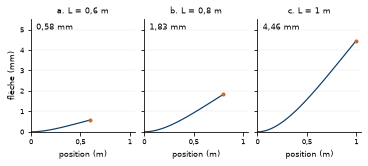

In [31]:
# Trois portées à échelle commune : flèche, valeur et extrémité.
fig, axes = plt.subplots(
    1, 3, sharey=True, figsize=(5.0, 2.2), layout="constrained"
)
for ax, lg, (x, y), b, c in zip(axes, longueurs, courbes, bouts, "abc"):
    ax.plot(x, y)
    ax.plot(lg, y[-1], "o")
    ax.set_title(f"{c}. L = " + f"{lg:g}".replace(".", ",") + " m")
    ax.set(xlim=(0, 1.05), ylim=(0, 5.5), xlabel="position (m)")
    ax.set_xticks([0, 0.5, 1])
    ax.annotate(f"{b} mm", (0.05, 0.91), xycoords="axes fraction")
# Étiquette verticale sur le premier panneau et virgule décimale.
axes[0].set_ylabel("flèche (mm)")
ms.virgule(fig, "xy")
fig.savefig(DOSSIER_FIGURES / "fig_c05_petits_multiples.pdf")

#### Une souplesse et son incertitude

In [32]:
# Essais synthétiques : déplacement linéaire bruité selon la force.
rng = np.random.default_rng(12)
force = np.linspace(0, 100, 40)
deplacement = 0.1 + 0.025 * force + rng.normal(0, 0.12, len(force))

# Régression linéaire, résidus et bande de confiance à 95 %.
pente, origine = np.polyfit(force, deplacement, 1)
ajuste = origine + pente * force
residu = deplacement - ajuste
dispersion = np.sqrt(np.sum(residu**2) / (len(force) - 2))
ecart = (force - force.mean())**2 / np.sum((force - force.mean())**2)
bande = 1.96 * dispersion * np.sqrt(1 / len(force) + ecart)
res = f"pente : {pente:.4f} mm/N ; résidus : {dispersion:.3f} mm"
print(res.replace(".", ","))

pente : 0,0245 mm/N ; résidus : 0,108 mm


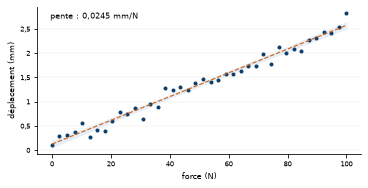

In [33]:
# Bande de confiance, points d'essais et droite ajustée.
fig, ax = plt.subplots(figsize=(5.0, 2.5), layout="constrained")
ax.fill_between(force, ajuste - bande, ajuste + bande, color=ms.PALE)
ax.plot(force, deplacement, "o")
ax.plot(force, ajuste, linestyle="dashed")

# Annotation de la pente, étiquettes et mise en forme des axes.
texte = f"pente : {pente:.4f} mm/N".replace(".", ",")
ax.annotate(texte, (0.04, 0.92), xycoords="axes fraction")
ax.set(xlabel="force (N)", ylabel="déplacement (mm)")
ms.virgule(ax, "xy")
fig.savefig(DOSSIER_FIGURES / "fig_c05_ajustement.pdf")

#### La vibration dépend de la direction

In [34]:
# Paramètres et échantillonnage angulaire autour de l'arbre.
majeure, mineure = 2.4, 0.8
orientation = 35.0
rad = np.deg2rad(orientation)
angles = np.linspace(0, 2 * np.pi, 361) + rad

# Amplitude en fonction de l'angle et recherche du maximum.
t = angles - rad
amplitudes = np.sqrt((majeure * np.cos(t))**2 + (mineure * np.sin(t))**2)
maxi = amplitudes.max()
texte = f"maximum : {maxi:.1f} mm ; direction : {orientation:g}°"
print(texte.replace(".", ","))

maximum : 2,4 mm ; direction : 35°


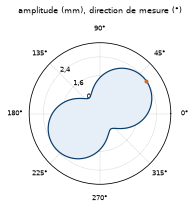

In [35]:
# Tracé polaire : courbe d'amplitude, fond et repérage du maximum.
fig, ax = plt.subplots(figsize=(5.0, 2.8), layout="constrained",
                       subplot_kw={"projection": "polar"})
ax.plot(angles, amplitudes)
ax.fill(angles, amplitudes, color=ms.PALE)
ax.plot([rad], [maxi], "o")
# Graduations angulaires, grille pointillée, limites radiales et virgule.
ax.set_thetagrids(range(0, 360, 45))
ax.grid(color="#8A8A8A", linestyle="dotted")
ax.set(ylim=(0, 3), yticks=[0.8, 1.6, 2.4])
ax.set_rlabel_position(135)
ax.set_title("amplitude (mm), direction de mesure (°)", pad=12)
ms.virgule(ax)
fig.savefig(DOSSIER_FIGURES / "fig_c05_polaire.pdf")

#### Une source chauffe une plaque

In [36]:
# Grille de calcul et paramètres de la source thermique gaussienne.
fond, elevation = 20.0, 65.0
x = np.linspace(-40, 40, 161)
y = np.linspace(-25, 25, 101)
gx, gy = np.meshgrid(x, y)
rx = (gx - 8) / 18
ry = (gy + 3) / 12

# Champ de température et niveaux réguliers pour la carte.
temperature = fond + elevation * np.exp(-(rx * rx + ry * ry))
niveaux = np.linspace(fond, fond + elevation, 12)
texte = f"grille : {temperature.shape} ; niveaux : {len(niveaux)} ; "
print(f"{texte}maximum : {temperature.max():.1f} °C".replace(".", ","))

grille : (101, 161) ; niveaux : 12 ; maximum : 85,0 °C


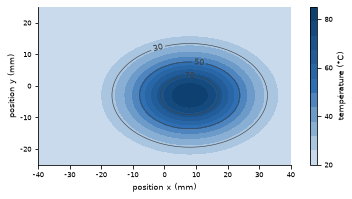

In [37]:
# Tracé du champ thermique, des isolignes et de la barre de couleur.
fig, ax = plt.subplots(figsize=(5.0, 2.65), layout="constrained")
champ = ax.contourf(gx, gy, temperature, levels=niveaux, cmap=ms.CARTE)
iso = ax.contour(gx, gy, temperature, levels=[30, 50, 70], colors="0.25",
                 linewidths=0.6)
ax.clabel(iso, fmt="%d")
barre = fig.colorbar(champ, ax=ax, ticks=[20, 40, 60, 80], format=ms.VIRGULE)
barre.set_label("température (°C)")

# Habillage des axes avec repère orthonormé et export.
ax.set(xlabel="position x (mm)", ylabel="position y (mm)", aspect="equal")
ms.virgule(ax, "xy")
fig.savefig(DOSSIER_FIGURES / "fig_c05_source_thermique.pdf")

#### La dispersion accompagne la moyenne

In [38]:
# Huit répétitions par vitesse selon une loi linéaire bruitée.
rng = np.random.default_rng(24)
vitesses = np.array([1000, 1500, 2000, 2500, 3000])
bruits = np.array([0.10, 0.13, 0.16, 0.19, 0.22])
tendance = 0.35 + 0.0007 * vitesses[:, None]
essais = tendance + rng.normal(size=(5, 8)) * bruits[:, None]

# Moyenne et dispersion mesurées sur chaque vitesse.
moyennes = essais.mean(axis=1)
ecarts = essais.std(axis=1, ddof=1)
repere = 2.2
dispersion = f"{ecarts.max():.3f}".replace(".", ",")
print(f"essais : {essais.shape} ; écart-type maximal : {dispersion} mm")

essais : (5, 8) ; écart-type maximal : 0,258 mm


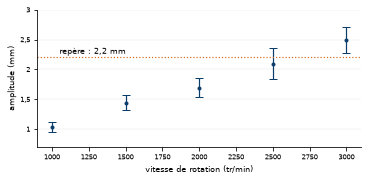

In [39]:
# Tracé des mesures avec barres d'erreur et seuil repère.
fig, ax = plt.subplots(figsize=(5.0, 2.4), layout="constrained")
ax.errorbar(vitesses, moyennes, yerr=ecarts, fmt="o", capsize=4)
ax.axhline(repere, color=ms.ORANGE, linestyle="dotted")
texte = f"repère : {repere:g} mm".replace(".", ",")
ax.text(1050, repere + 0.06, texte)

# Habillage des axes et enregistrement du graphique.
ax.set(xlabel="vitesse de rotation (tr/min)", ylabel="amplitude (mm)")
ax.set_ylim(0.7, 3.0)
ms.virgule(ax, "xy")
fig.savefig(DOSSIER_FIGURES / "fig_c05_essais_repetes.pdf")

### Figures de métier

#### Limite conventionnelle à 0,2 %

In [40]:
# Ramberg-Osgood : calcul de déformation et écart à la droite.
module, rp, n, decalage = 210000.0, 350.0, 10, 0.002
contrainte = np.linspace(0, 410, 701)
deformation = contrainte / module + decalage * (contrainte / rp)**n
ecart = deformation - contrainte / module - decalage

# Limite conventionnelle Rp0,2 par interpolation au zéro d'écart.
i = np.flatnonzero(np.diff(np.sign(ecart)))[0]
limite = np.interp(0, ecart[i:i + 2], contrainte[i:i + 2])
point = 100 * np.interp(limite, contrainte, deformation)
print(f"Rp théorique : {rp:g} MPa ; décalage : "
      f"{100 * decalage:g} %".replace(".", ","))
print(f"intersection : {limite:.3f} MPa ; écart de grille : "
      f"{abs(limite - rp):.3f} MPa".replace(".", ","))

Rp théorique : 350 MPa ; décalage : 0,2 %
intersection : 349,999 MPa ; écart de grille : 0,001 MPa


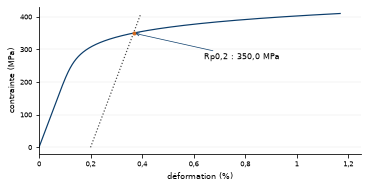

In [41]:
# Courbe de traction, droite élastique décalée et point conventionnel.
fig, ax = plt.subplots(figsize=(5.0, 2.5), layout="constrained")
droite = 100 * (contrainte / module + decalage)
ax.plot(100 * deformation, contrainte)
ax.plot(droite, contrainte, ":", color=ms.GRIS)
ax.plot(point, limite, "o")

# Repérage de la limite conventionnelle Rp0,2 et mise en forme.
texte = f"Rp0,2 : {limite:.1f} MPa".replace(".", ",")
ax.annotate(texte, (point, limite), (0.64, 270), arrowprops=ms.FLECHE)
ax.set(xlabel="déformation (%)", ylabel="contrainte (MPa)", xlim=(0, 1.25))
ms.virgule(ax, "xy")
fig.savefig(DOSSIER_FIGURES / "fig_c05_traction.pdf")

#### Rugosité selon avance et rayon

In [42]:
# Grille et rugosité théorique en tournage selon l'avance et le rayon.
avances = np.linspace(0.05, 0.40, 30)
rayons = np.linspace(0.4, 1.2, 30)
avance, rayon = np.meshgrid(avances, rayons)
ra = 1000 * avance**2 / (32 * rayon)
f0, r0 = 0.2, 0.8
ra0 = 1000 * f0**2 / (32 * r0)
# Affichage du point repère et du rapport d'avance min/max.
msg1 = f"f : {f0:g} mm/tr ; r : {r0:g} mm ; Ra : {ra0:.4f} µm"
print(msg1.replace(".", ","))
rap = (avances[-1] / avances[0])**2
txt = f"avance min/max : {avances[0]:g} ; {avances[-1]:g} mm/tr ; "
print(f"{txt}rapport Ra : {rap:g}".replace(".", ","))

f : 0,2 mm/tr ; r : 0,8 mm ; Ra : 1,5625 µm
avance min/max : 0,05 ; 0,4 mm/tr ; rapport Ra : 64


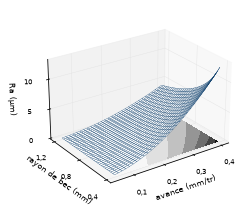

In [43]:
# Surface 3D de la rugosité et projection en courbes de niveau.
fig = plt.figure(figsize=(5.0, 2.8), layout="constrained")
ax = fig.add_subplot(projection="3d")
s = ax.plot_surface(avance, rayon, ra, color="white", shade=False)
s.set(edgecolor=ms.BLEU, linewidth=0.3)
ax.contourf(avance, rayon, ra, zdir="z", offset=0, levels=6, cmap="Greys")
ax.view_init(elev=25, azim=-125)
ax.set_box_aspect((1.3, 1, 0.8), zoom=1.0)
# Habillage des axes, graduations et virgules décimales.
ax.set_xlabel("avance (mm/tr)", labelpad=0)
ax.set_ylabel("rayon de bec (mm)", labelpad=-4)
ax.set_zlabel("Ra (µm)", labelpad=0)
ax.set(xticks=[0.1, 0.2, 0.3, 0.4], yticks=[0.4, 0.8, 1.2], zticks=[0, 5, 10])
ms.virgule(ax, "xyz")
fig.savefig(DOSSIER_FIGURES / "fig_c05_rugosite.pdf")

#### Diagramme de Pareto des défauts

In [44]:
# Effectifs d'illustration des rebuts d'une ligne de soudage.
defauts = ["porosité", "manque\nde fusion", "fissure", "morsure", "projection"]
effectifs = np.array([300, 180, 100, 50, 20])
cumul = 100 * np.cumsum(effectifs) / effectifs.sum()

# Nombre de catégories pour atteindre le seuil de 80 % de pièces au rebut.
seuil = 80
nb = np.searchsorted(cumul, seuil) + 1
valeurs = " ; ".join(str(v) for v in effectifs)
print("effectifs :", valeurs)
atteint = f"{cumul[nb - 1]:.1f}".replace(".", ",")
print(f"seuil : {seuil} % ; catégories : {nb} ; cumul : {atteint} %")

effectifs : 300 ; 180 ; 100 ; 50 ; 20
seuil : 80 % ; catégories : 3 ; cumul : 89,2 %


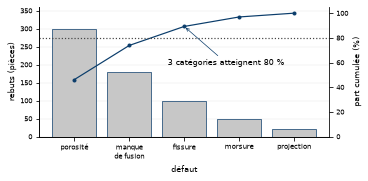

In [45]:
# Pareto : effectifs en barres sur l'axe principal, part cumulée au-dessus.
fig, ax = plt.subplots(figsize=(5.0, 2.4), layout="constrained")
ax.bar(defauts, effectifs, color="0.78", edgecolor=ms.BLEU)
ax.set(xlabel="défaut", ylabel="rebuts (pièces)", ylim=(0, 360))
ax_c = ax.twinx()
ax_c.grid(False)
ax_c.spines["right"].set_visible(True)
ax_c.plot(defauts, cumul, "o-")
# Ligne d'objectif, flèche d'annotation et formatage de l'axe secondaire.
ax_c.axhline(seuil, color="#444444", linestyle="dotted")
ax_c.annotate(f"{nb} catégories atteignent {seuil} %",
              (nb - 1, cumul[nb - 1]), (1.7, 58), arrowprops=ms.FLECHE)
ax_c.set(ylabel="part cumulée (%)", ylim=(0, 105))
ms.virgule(fig, "y")
fig.savefig(DOSSIER_FIGURES / "fig_c05_pareto.pdf")

#### Carte de contrôle de la moyenne

In [46]:
# Diamètre = cible + bruit normal, puis une dérive sur les 5 derniers groupes.
rng = np.random.default_rng(31)
mesures = rng.normal(20.000, 0.020, (25, 5))
mesures[-5:] += np.linspace(0.015, 0.060, 5)[:, None]
moyennes = mesures.mean(axis=1)

# Limites à trois écarts-types, estimées sur les vingt premiers sous-groupes.
centre = mesures[:20].mean()
ecart = mesures[:20].std(ddof=1) / np.sqrt(5)
bas, haut = centre - 3 * ecart, centre + 3 * ecart
hors = (moyennes < bas) | (moyennes > haut)
numeros = np.arange(1, 26)
premier = numeros[hors][0]
print(f"limites (mm) : {bas:.4f} ; {haut:.4f}".replace(".", ","))
print(f"premier hors limites : {premier}")

limites (mm) : 19,9749 ; 20,0223
premier hors limites : 22


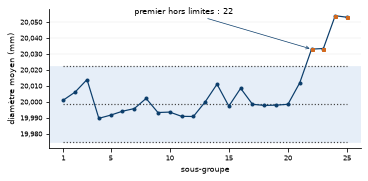

In [47]:
# Bande de contrôle, repères et moyennes des sous-groupes.
fig, ax = plt.subplots(figsize=(5.0, 2.4), layout="constrained")
ax.axhspan(bas, haut, color=ms.PALE)
ax.hlines([bas, centre, haut], 1, 25, linestyles="dotted")
ax.plot(numeros, moyennes, "o-")
ax.plot(numeros[hors], moyennes[hors], "s")

# Annotation du premier point hors limites et réglage des axes.
texte = f"premier hors limites : {premier}"
point = (premier, moyennes[premier - 1])
ax.annotate(texte, point, (7, 20.055), arrowprops=ms.FLECHE)
ax.set(xlabel="sous-groupe", ylabel="diamètre moyen (mm)")
ax.set_xticks([1, 5, 10, 15, 20, 25])
ms.virgule(ax, fmt=".3f")
fig.savefig(DOSSIER_FIGURES / "fig_c05_carte_controle.pdf")

#### Planning d'atelier

In [48]:
# Tâches (début, durée, nom) et arrêts non planifiés, en heures.
poste = 8
taches = [[(0, 1.5, "P1"), (1.5, 1, "P2"), (3, 2, "P3"), (5.5, 2, "P4")],
          [(0.5, 1.5, "P5"), (2, 2, "P6"), (4.5, 1, "P7"), (6, 1.5, "P8")],
          [(0, 2, "P9"), (2.5, 1, "P10"), (3.5, 2, "P11"), (6, 1, "P12")]]
arrets = [[(2.5, 0.5)], [(4, 0.5), (5.5, 0.5)], [(2, 0.5)]]
coul = [ms.BLEU, "#2F6FB3", ms.GRIS]
# Durée des arrêts et occupation de chaque machine, en pourcentage du poste.
arret_h = sum(d for liste in arrets for _, d in liste)
occupation = [100 * sum(t[1] for t in liste) / poste for liste in taches]
valeurs = " ; ".join(f"{v:.2f}" for v in occupation)
print("arrêts (h) :", str(arret_h).replace(".", ","))
print("occupation (%) :", valeurs.replace(".", ","))

arrêts (h) : 2,0
occupation (%) : 81,25 ; 75,00 ; 75,00


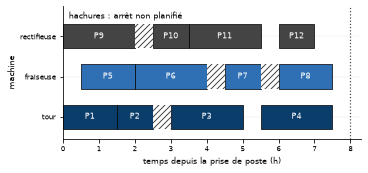

In [49]:
# Une barre par tâche, une barre hachurée par arrêt, le nom de la pièce dessus.
fig, ax = plt.subplots(figsize=(5.0, 2.3), layout="constrained")
for i, liste in enumerate(taches):
    ax.broken_barh([t[:2] for t in liste], (i - 0.3, 0.6), fc=coul[i], ec="k")
    ax.broken_barh(arrets[i], (i - 0.3, 0.6), fc="white", hatch="////")
    for debut, duree, piece in liste:
        ax.text(debut + duree / 2, i - 0.05, piece, color="white", ha="center")
# Fin de poste, légende des hachures, intitulés et graduations.
ax.axvline(poste, linestyle="dotted")
ax.annotate("hachures : arrêt non planifié", (0.02, 0.96),
            xycoords="axes fraction", va="top")
ax.set(xlabel="temps depuis la prise de poste (h)", ylabel="machine",
       xlim=(0, 8.3), ylim=(-0.55, 2.75))
ax.set_yticks([0, 1, 2], ["tour", "fraiseuse", "rectifieuse"])
fig.savefig(DOSSIER_FIGURES / "fig_c05_planning.pdf")

#### Marge de phase d'un asservissement

In [50]:
# Boucle ouverte : gain, intégrateur, premier ordre de constante tau_s (s).
gain, tau_s = 20.0, 0.05
puls = np.logspace(-1, 3, 600)
boucle = gain / (1j * puls * (1 + 1j * puls * tau_s))
g_db, ph = 20 * np.log10(np.abs(boucle)), np.degrees(np.angle(boucle))

# Recherche de la pulsation de coupure et de la marge de phase.
coupure = np.interp(0, g_db[::-1], puls[::-1])
marge = 180 + np.interp(coupure, puls, ph)
exacte = gain * np.sqrt(2 / (1 + np.hypot(1, 2 * gain * tau_s)))
theorie = 90 - np.degrees(np.arctan(tau_s * exacte))
txt_coup = f"coupure : {coupure:.4f} rad/s ; exacte : {exacte:.4f} rad/s"
print(txt_coup.replace(".", ","))
print(f"marge : {marge:.4f}° ; exacte : {theorie:.4f}°".replace(".", ","))

coupure : 15,7231 rad/s ; exacte : 15,7230 rad/s
marge : 51,8273° ; exacte : 51,8273°


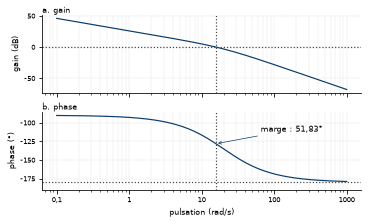

In [51]:
# Tracé du diagramme de Bode avec gain et phase, repères de coupure.
fig, axes = plt.subplots(2, sharex=True, figsize=(5, 3), layout="constrained")
for ax, v, t, y0 in zip(axes, (g_db, ph), ("a. gain", "b. phase"), (0, -180)):
    ax.semilogx(puls, v)
    ax.set_title(t, loc="left", pad=2)
    ax.set_ylabel(f"{t[3:]} ({'dB' if y0 == 0 else '°'})")
    ax.axhline(y0, linestyle="dotted")
    ax.axvline(coupure, linestyle="dotted")
    ax.grid(which="both", axis="x")
# Limites, annotation de la marge et formatage.
axes[1].set(xlabel="pulsation (rad/s)", ylim=(-190, -85))
txt = f"marge : {marge:.2f}°".replace(".", ",")
axes[1].annotate(txt, (coupure, marge - 180), (65, -112), arrowprops=ms.FLECHE)
ms.virgule(fig, "xy")
fig.savefig(DOSSIER_FIGURES / "fig_c05_bode.pdf")

#### Spectrogramme d'une montée en régime

In [52]:
# Rampe de fréquence (20 + 8 t, en Hz), harmonique et bruit blanc.
from matplotlib.mlab import specgram
t = np.arange(5000) / 500
phase = 2 * np.pi * (20 * t + 4.0 * t**2)
bruit = 0.12 * np.random.default_rng(52).normal(size=5000)
signal = np.sin(phase) + 0.5 * np.sin(2 * phase) + bruit
densite, freq, centres = specgram(signal, NFFT=256, Fs=500, noverlap=192)
db = 10 * np.log10(densite)  # densité spectrale en décibels
plancher = 5 * np.ceil((np.median(db) + 10) / 5)  # médiane + 10 dB
print(f"plancher : {plancher:g} dB ; résolution : {500 / 256:.2f} Hz"
      .replace(".", ","))
pics = freq[np.argmax(densite[:, [0, -1]], axis=0)]
pres = 20 + 8.0 * centres[[0, -1]]
print(f"pics (Hz) : {pics[0]:.2f} ; {pics[1]:.2f}".replace(".", ","))
print(f"prescrites (Hz) : {pres[0]:.2f} ; {pres[1]:.2f}".replace(".", ","))

plancher : -30 dB ; résolution : 1,95 Hz
pics (Hz) : 21,48 ; 97,66
prescrites (Hz) : 22,05 ; 97,82


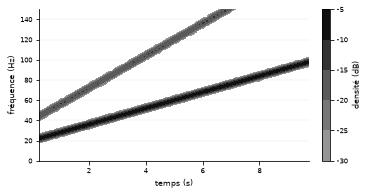

In [53]:
# Niveaux de contour, tracé du champ, barre de couleur et sauvegarde.
niveaux = np.arange(plancher, db.max() + 5, 5)
fig, ax = plt.subplots(figsize=(5.0, 2.6), layout="constrained")
vmin = plancher - 20
champ = ax.contourf(centres, freq, db, niveaux, cmap="Greys", vmin=vmin)
champ.set(edgecolor="face", linewidth=0.2)
fig.colorbar(champ, ax=ax, format=ms.VIRGULE, label="densité (dB)")
ax.set(xlabel="temps (s)", ylabel="fréquence (Hz)", ylim=(0, 150))
fig.savefig(DOSSIER_FIGURES / "fig_c05_spectrogramme.pdf")

#### Écoulement autour d'un cylindre

In [54]:
# Grille de calcul et masque pour l'intérieur du tube.
rayon, u = 20.0, 5.0
pos = np.linspace(-80, 80, 161)
x, y = np.meshgrid(pos, pos)
r2 = x**2 + y**2
r4 = np.ma.masked_where(r2 < rayon**2, np.maximum(r2, rayon**2)**2)

# Vitesse de l'écoulement potentiel et écart à la théorie.
vx = u * (1 - rayon**2 * (x**2 - y**2) / r4)
vy = -2 * u * rayon**2 * x * y / r4
vitesse = np.sqrt(vx**2 + vy**2)
rapport = vitesse.max() / u
ecart = 100 * (2 - rapport) / 2
print(f"maximum / U : {rapport:.4f}".replace(".", ","))
print(f"théorie : 2 U ; écart de grille : {ecart:.2f} %".replace(".", ","))

maximum / U : 2,0000
théorie : 2 U ; écart de grille : 0,00 %


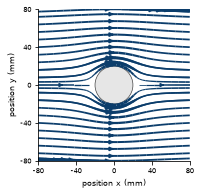

In [55]:
# Tracé des lignes de courant et du contour du cylindre.
fig, ax = plt.subplots(figsize=(5.0, 2.6), layout="constrained")
ax.streamplot(pos, pos, vx, vy, density=0.7, linewidth=1.8 * vitesse / u,
              color=ms.BLEU, arrowsize=0.65, broken_streamlines=False)
ax.add_patch(plt.Circle((0, 0), rayon, facecolor="0.9", edgecolor=ms.GRIS))

# Configuration des axes, repères orthonormés et sauvegarde.
bornes = [-80, -40, 0, 40, 80]
ax.set(xlabel="position x (mm)", ylabel="position y (mm)", aspect="equal")
ax.set(xlim=(-80, 80), ylim=(-80, 80), xticks=bornes, yticks=bornes)
ax.grid(False)
ms.virgule(ax, "xy")
fig.savefig(DOSSIER_FIGURES / "fig_c05_cylindre.pdf")

## Essais des fiches de fonction du chapitre

Chaque fiche du livre donne l'appel minimal d'une fonction. Les cellules suivantes rejouent ces appels, avec les mêmes lignes de code et la même sortie que la fiche : changez une valeur et relisez le résultat.

### Fiche F05-1 : Figure et axes (`matplotlib.pyplot.subplots`)

2 cadres, M max = 2500,0 N m
True


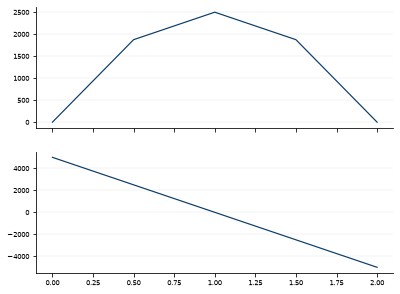

In [56]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(0, 2.0, 5)                # abscisses, m
M = 5e3 * x * (2.0 - x) / 2               # moment fléchissant, N.m
fig, axs = plt.subplots(nrows=2, sharex=True)
axs[0].plot(x, M)                         # affectation au premier cadre
V = 5e3 * (1.0 - x)                      # effort tranchant, N
axs[1].plot(x, V)                         # second cadre
print(f"{len(fig.axes)} cadres, M max = {M.max():.1f} N m".replace(".", ","))
print(np.isclose(M.max(), 5e3 * 2.0**2 / 8)) # contrôle du maximum